In [16]:
# CodeAlpha Internship – Task 3
# Data Visualization

df_clean.to_csv("Ecommerce_Cleaned_Data.csv", index=False)

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv("Ecommerce_Cleaned_Data.csv")

df_clean["OrderDate"] = pd.to_datetime(df_clean["OrderDate"])

print(df_clean.shape)
df_clean.head()

(500, 14)


,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
0,ORD0001,2025-02-01,C070,Customer_021,Laptop,Electronics,Jaipur,North,4,58944.58,0.10,212200.49,UPI,Completed
1,ORD0002,2025-02-16,C084,Customer_046,Water Bottle,Accessories,Chennai,South,4,475.75,0.10,1712.70,Debit Card,Completed
2,ORD0003,2025-07-19,C045,Customer_046,Smartphone,Electronics,Ahmedabad,West,4,23420.15,0.15,79628.51,Credit Card,Completed
3,ORD0004,2025-08-19,C017,Customer_076,Notebook,Stationery,Ahmedabad,West,1,85.24,0.05,80.98,Cash,Completed
4,ORD0005,2025-10-05,C020,Customer_037,Laptop,Electronics,Ahmedabad,West,3,58062.22,0.20,139349.33,Debit Card,Completed


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv("Ecommerce_Cleaned_Data.csv")

df_clean["OrderDate"] = pd.to_datetime(df_clean["OrderDate"])

print("Cleaned Dataset Loaded Successfully!")
print("Dataset Shape:", df_clean.shape)

df_clean.head()

Cleaned Dataset Loaded Successfully!
Dataset Shape: (500, 14)


,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
0,ORD0001,2025-02-01,C070,Customer_021,Laptop,Electronics,Jaipur,North,4,58944.58,0.10,212200.49,UPI,Completed
1,ORD0002,2025-02-16,C084,Customer_046,Water Bottle,Accessories,Chennai,South,4,475.75,0.10,1712.70,Debit Card,Completed
2,ORD0003,2025-07-19,C045,Customer_046,Smartphone,Electronics,Ahmedabad,West,4,23420.15,0.15,79628.51,Credit Card,Completed
3,ORD0004,2025-08-19,C017,Customer_076,Notebook,Stationery,Ahmedabad,West,1,85.24,0.05,80.98,Cash,Completed
4,ORD0005,2025-10-05,C020,Customer_037,Laptop,Electronics,Ahmedabad,West,3,58062.22,0.20,139349.33,Debit Card,Completed


In [19]:
# 1. Product-wise Sales
product_sales = (
    df_clean.groupby("ProductName")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

# 2. Monthly Sales
monthly_sales = (
    df_clean.groupby(df_clean["OrderDate"].dt.month)["Sales"]
    .sum()
    .sort_index()
)

# 3. Category-wise Sales
category_sales = df_clean.groupby("Category")["Sales"].sum()

# 4. Correlation
correlation = df_clean[
    ["Quantity", "UnitPrice", "DiscountPct", "Sales"]
].corr()

print("All analysis variables created successfully!")

All analysis variables created successfully!


In [20]:
print(product_sales.head())
print(monthly_sales)
print(category_sales)
print(correlation)

ProductName
Laptop          8490437.56
Smartphone      2587931.86
Desk            1111717.71
Office Chair     724453.52
Headphones       325447.50
Name: Sales, dtype: float64
OrderDate
1     1128235.65
2     1041647.27
3     1602942.95
4     1190597.40
5     1243336.00
6      896804.12
7      873787.58
8      687059.29
9     1280092.88
10    2074194.55
11     907481.50
12     686850.71
Name: Sales, dtype: float64
Category
Accessories      267642.01
Electronics    11480202.72
Furniture       1836171.23
Stationery        29013.94
Name: Sales, dtype: float64
             Quantity  UnitPrice  DiscountPct     Sales
Quantity     1.000000   0.004062    -0.003991  0.246631
UnitPrice    0.004062   1.000000    -0.054881  0.874928
DiscountPct -0.003991  -0.054881     1.000000 -0.085486
Sales        0.246631   0.874928    -0.085486  1.000000


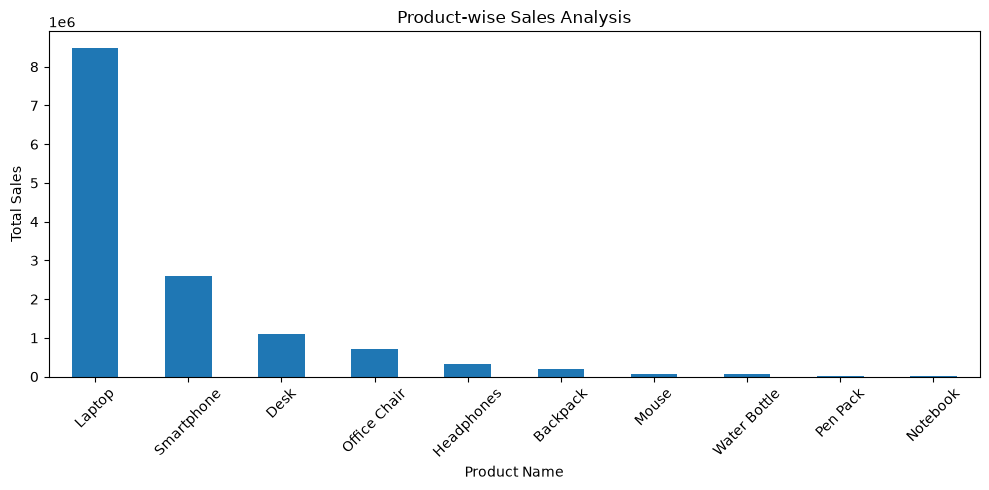

In [21]:
plt.figure(figsize=(10, 5))

product_sales.plot(kind="bar")

plt.title("Product-wise Sales Analysis")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

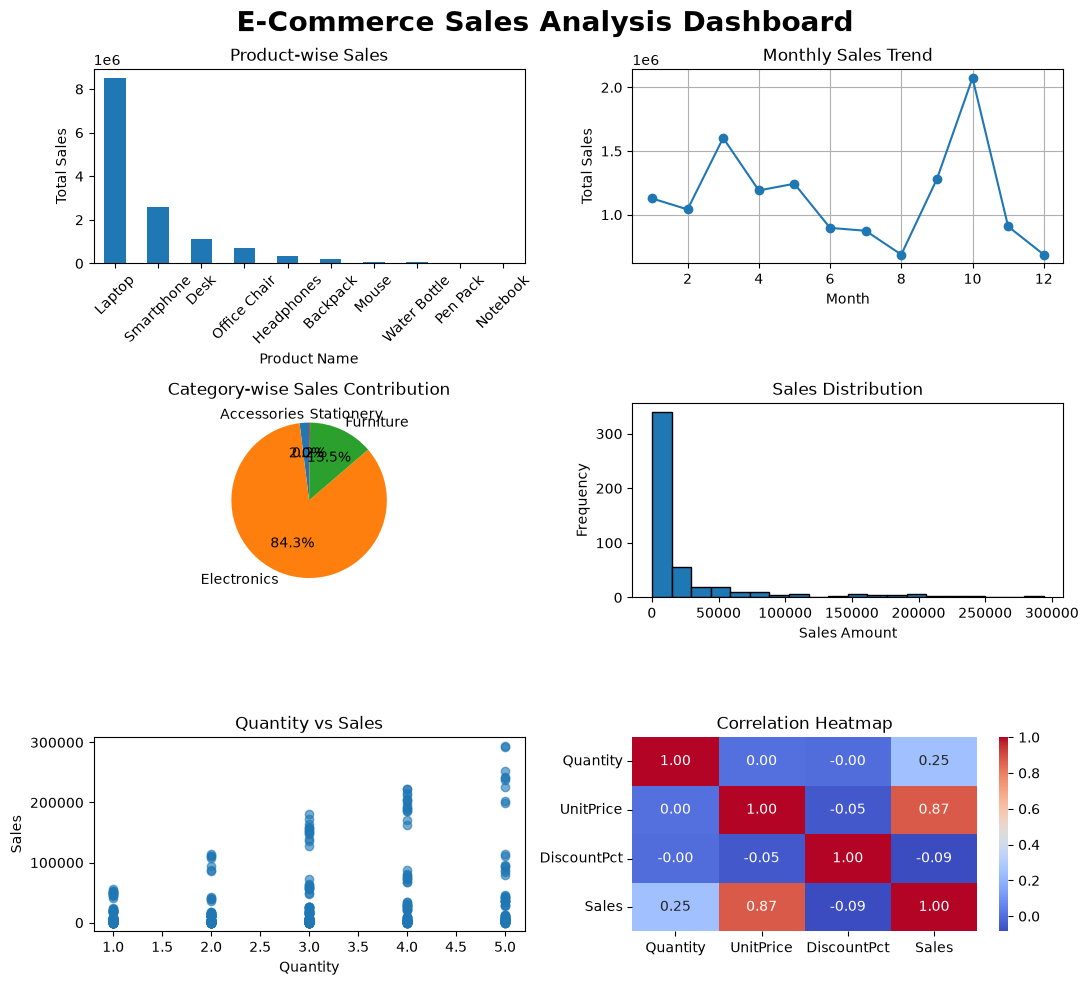

In [26]:

# Create a 6-chart dashboard
fig, axes = plt.subplots(3, 2, figsize=(11, 10))

# 1. Product-wise Sales Bar Chart
product_sales.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Product-wise Sales")
axes[0, 0].set_xlabel("Product Name")
axes[0, 0].set_ylabel("Total Sales")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Monthly Sales Line Chart
axes[0, 1].plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)
axes[0, 1].set_title("Monthly Sales Trend")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Total Sales")
axes[0, 1].grid(True)

# 3. Category-wise Sales Pie Chart
axes[1, 0].pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 0].set_title("Category-wise Sales Contribution")

# 4. Sales Distribution Histogram
axes[1, 1].hist(
    df_clean["Sales"],
    bins=20,
    edgecolor="black"
)
axes[1, 1].set_title("Sales Distribution")
axes[1, 1].set_xlabel("Sales Amount")
axes[1, 1].set_ylabel("Frequency")

# 5. Quantity vs Sales Scatter Plot
axes[2, 0].scatter(
    df_clean["Quantity"],
    df_clean["Sales"],
    alpha=0.6
)
axes[2, 0].set_title("Quantity vs Sales")
axes[2, 0].set_xlabel("Quantity")
axes[2, 0].set_ylabel("Sales")

# 6. Correlation Heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    ax=axes[2, 1]
)
axes[2, 1].set_title("Correlation Heatmap")

# Main Dashboard Title
plt.suptitle(
    "E-Commerce Sales Analysis Dashboard",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [24]:

print("===== DATA VISUALIZATION INSIGHTS =====")

print("Highest Sales Product:", product_sales.idxmax())
print("Lowest Sales Product:", product_sales.idxmin())
print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Sales Category:", category_sales.idxmax())
print("Total Sales:", round(df_clean["Sales"].sum(), 2))
print("Average Sales:", round(df_clean["Sales"].mean(), 2))


===== DATA VISUALIZATION INSIGHTS =====
Highest Sales Product: Laptop
Lowest Sales Product: Notebook
Highest Sales Month: 10
Highest Sales Category: Electronics
Total Sales: 13613029.9
Average Sales: 27226.06


# CodeAlpha Internship – Task 3
# Data Visualization

## 1. Project Objective
The objective of this task is to visualize e-commerce sales data using Python charts and graphs to understand business performance and identify meaningful patterns.

## 2. Dataset
- Dataset: E-Commerce Sales Dataset
- Records: 500
- Columns: 14
- Data source: Cleaned dataset from Task 2

## 3. Tools and Technologies
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 4. Visualizations Created

1. Bar Chart: Product-wise Sales Analysis
2. Line Chart: Monthly Sales Trend
3. Pie Chart: Category-wise Sales Contribution
4. Histogram: Sales Distribution
5. Scatter Plot: Quantity vs Sales
6. Heatmap: Correlation Analysis

## 5. Dashboard
Created a combined dashboard containing all six visualizations to present sales performance in one view.

## 6. Key Insights
- Identified the highest and lowest sales products.
- Analyzed monthly sales trends.
- Compared category-wise sales contribution.
- Examined sales distribution.
- Studied the relationship between quantity and sales.
- Analyzed correlations between numerical variables.

## 7. Conclusion
Data visualization transformed the cleaned e-commerce dataset into meaningful graphical insights. The charts and dashboard helped understand product performance, sales trends, category contribution, and relationships between numerical variables.